# PROG8431 — Solutions to Highway Congestion
## Workshop C+D: Data Transformation and Linear Regression

**Group members:** Jasper Lim (9117038), John Buni (9115726), Eche Oji (9078881)  
**GitHub repository:** https://github.com/JohnBuni/Data-Analysis-Project-Group4.git

**Purpose.** Transform and augment the 2024 Ontario provincial highway segment data with the 1988–2024 traffic-volume dataset. Predict 2024 Annual Average Daily Traffic (AADT), compare simple linear regression models, and compare full and reduced multiple linear regression models.

**Secondary data source:** https://www.library.mto.gov.on.ca/SydneyPLUS/TechPubs/Portal/tp/tvSplash.aspx

## 1. Data setup and exploration

Both datasets are in the `data` folder. The historical CSV is read as text before numerical conversion. Inspect sample records, missing values and descriptive statistics.

Required packages: pandas, NumPy, matplotlib, seaborn, SciPy, statsmodels, scikit-learn and openpyxl. Install missing packages before running the notebook.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the original and historical datasets
df = pd.read_excel(
    "./data/Provincial Highways Traffic Volumes 2024 AADT Only.xlsx"
)

historical = pd.read_csv(
    "./data/Traffic_Volumes_1988-2024.csv",
    encoding="cp1252",
    dtype=str
)

# Examine dataset dimensions and sample records
print("Original dataset shape:", df.shape)
display(df.head())

print("Historical dataset shape:", historical.shape)
display(historical.head())

Original dataset shape: (2712, 5)


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


Historical dataset shape: (62548, 25)


,LHRS,Offset,Year,Hwy No,Hwy No Suffix,Hwy. Type,Description,Station #,Region,Length,...,Design Hr. Dir Split %,Design Hr. Dir Split Higher Volume Direction,AADT,SADT,SAWDT,WADT,Truck %,Truck AADTT,Alpha Code,Count Code
0,10000,0.000,1988,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"19,800","25,700","24,200","16,600",21.8,"4,300",B,9
1,10000,0.000,1989,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"20,200","25,700","24,400","17,400",20.6,"4,150",B,9
2,10000,0.000,1990,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,100","27,600","26,100","19,200",18.3,"4,050",B,9
3,10000,0.000,1991,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,100","27,800","27,600","19,200",19.2,"4,250",B,9
4,10000,0.000,1992,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,200","27,300","26,400","19,300",21.4,"4,750",B,9


In [2]:
# Examine missing values and numerical summaries
print("Original dataset missing values (%):")
display((df.isnull().mean() * 100).round(2))

print("\nOriginal dataset descriptive statistics:")
display(df.describe().round(2))

print("\nHistorical dataset missing values (%):")
display((historical.isnull().mean() * 100).round(2))

Original dataset missing values (%):


Highway                      11.21
Location Description From    11.21
Location Description To      11.21
Distance (KM)                22.53
2024 AADT                    33.26
dtype: float64


Original dataset descriptive statistics:


,Distance (KM),2024 AADT
count,2101.00,1810.00
mean,9.12,31808.32
std,13.86,66712.33
min,0.10,10.00
25%,2.07,2012.50
50%,4.74,7350.00
75%,10.20,23500.00
max,178.60,511400.00



Historical dataset missing values (%):


LHRS                                             0.00
Offset                                           0.00
Year                                             0.00
Hwy No                                           0.00
Hwy No Suffix                                   97.39
Hwy. Type                                        0.00
Description                                      0.00
Station #                                        0.85
Region                                           0.00
Length                                           0.85
Conn. Link Length                               99.64
Secondary Description                           99.07
PDCS #                                           0.82
Pattern Type                                     0.82
DHV %                                            2.29
Design Hr. Dir Split %                           2.40
Design Hr. Dir Split Higher Volume Direction    73.76
AADT                                             2.29
SADT                        

## 2. Data cleaning and augmentation

The Ontario Ministry of Transportation historical dataset (1988–2024) adds annual traffic measurements, seasonal volumes, truck traffic and highway characteristics. Only observations through 2023 supply predictors for 2024 AADT. Remove original segments with missing essential information or nonpositive distance/AADT.

In [3]:
# Remove original records with missing essential values
df_clean = df.dropna(subset=[
    "Highway",
    "Location Description From",
    "Distance (KM)",
    "2024 AADT"
]).copy()

# Retain positive distance and traffic measurements
df_clean = df_clean[
    (df_clean["Distance (KM)"] > 0) &
    (df_clean["2024 AADT"] > 0)
].copy()

# Create a working copy of the historical dataset
historical_clean = historical.copy()

# Convert numerical columns from text to numeric values
numeric_columns = [
    "Year", "Length", "AADT", "SADT", "SAWDT", "WADT",
    "Truck %", "Truck AADTT", "DHV %",
    "Design Hr. Dir Split %"
]

for column in numeric_columns:
    historical_clean[column] = pd.to_numeric(
        historical_clean[column].str.replace(",", "", regex=False),
        errors="coerce"
    )

# Separate historical predictor data from 2024 records
historical_prior = historical_clean[
    historical_clean["Year"] < 2024
].copy()

print("Original rows before cleaning:", len(df))
print("Original rows after cleaning:", len(df_clean))
print("Historical rows before 2024:", len(historical_prior))

display(historical_prior[numeric_columns].describe().round(2))

Original rows before cleaning: 2712
Original rows after cleaning: 1810
Historical rows before 2024: 60165


,Year,Length,AADT,SADT,SAWDT,WADT,Truck %,Truck AADTT,DHV %,Design Hr. Dir Split %
count,60165.00,60150.00,59308.00,59308.00,59308.00,59308.00,59301.00,59308.00,59308.00,59237.00
mean,2005.68,9.32,25454.31,28677.82,28888.12,22769.68,14.02,3150.19,11.51,46.81
std,10.22,12.68,54595.25,58786.97,60542.46,50311.52,9.67,6025.86,3.29,24.56
min,1988.00,0.10,10.00,20.00,20.00,10.00,0.00,0.00,0.00,0.00
25%,1997.00,2.25,1950.00,2550.00,2450.00,1550.00,8.00,210.00,10.00,51.00
50%,2006.00,5.21,6450.00,7900.00,7600.00,5400.00,11.00,720.00,10.00,55.00
75%,2014.00,10.78,18800.00,22600.00,22100.00,16125.00,17.00,2200.00,12.00,60.00
max,2023.00,150.30,501200.00,548300.00,547000.00,452300.00,164.40,49600.00,28.00,101.00


### Matching highway segments

Normalize highway identifiers and starting-location descriptions to create a common merge key. Check duplicate keys and matching coverage before combining the datasets.

In [4]:
# Standardize highway identifiers
def normalize_highway(values):
    return (
        values.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"\.0$", "", regex=True)
        .replace({"QEW": "1"})
    )

# Standardize location descriptions
def normalize_location(values):
    return (
        values.astype("string")
        .str.upper()
        .str.replace(r"[^A-Z0-9]+", " ", regex=True)
        .str.strip()
    )

# Create matching identifiers in the original dataset
df_clean["Highway_Key"] = normalize_highway(df_clean["Highway"])

df_clean["Location_Key"] = normalize_location(
    df_clean["Location Description From"]
)

df_clean["Merge_Key"] = (
    df_clean["Highway_Key"] + "|" + df_clean["Location_Key"]
)

# Create matching identifiers in the historical dataset
historical_clean["Highway_Key"] = normalize_highway(
    historical_clean["Hwy No"]
) + historical_clean["Hwy No Suffix"].fillna("").str.strip().str.upper()

historical_clean["Location_Key"] = normalize_location(
    historical_clean["Description"]
)

historical_clean["Merge_Key"] = (
    historical_clean["Highway_Key"] + "|" +
    historical_clean["Location_Key"]
)

# Separate records for matching and historical predictors
historical_2024 = historical_clean[
    historical_clean["Year"] == 2024
].copy()

historical_prior = historical_clean[
    historical_clean["Year"] < 2024
].copy()

# Check matching coverage
matched = df_clean["Merge_Key"].isin(historical_2024["Merge_Key"])
matched_prior = df_clean["Merge_Key"].isin(historical_prior["Merge_Key"])

print("Cleaned highway segments:", len(df_clean))
print("Segments matching 2024 records:", matched.sum())
print("2024 match percentage:", round(matched.mean() * 100, 2))
print("Segments matching historical records:", matched_prior.sum())

# Identify potentially ambiguous identifiers
print("\nDuplicate original identifiers:",
      df_clean["Merge_Key"].duplicated().sum())

print("Duplicate 2024 identifiers:",
      historical_2024["Merge_Key"].duplicated().sum())

print("Duplicate historical segment-year identifiers:",
      historical_prior.duplicated(["Merge_Key", "Year"]).sum())

Cleaned highway segments: 1810
Segments matching 2024 records: 1809
2024 match percentage: 99.94
Segments matching historical records: 1809

Duplicate original identifiers: 0
Duplicate 2024 identifiers: 0
Duplicate historical segment-year identifiers: 0


### Historical feature construction

Summarize historical records into one row per segment: selected annual traffic volumes, historical statistics, growth, seasonal traffic, vehicle composition and categorical highway characteristics. Percentages outside 0–100 are treated as missing.

In [5]:
# Replace invalid percentage measurements with missing values
percentage_columns = [
    "Truck %",
    "DHV %",
    "Design Hr. Dir Split %"
]

for column in percentage_columns:
    invalid = (
        (historical_prior[column] < 0) |
        (historical_prior[column] > 100)
    )
    historical_prior.loc[invalid, column] = np.nan

# Select historical years to represent long-term traffic changes
selected_years = [
    1988, 1995, 2000, 2005, 2010, 2015,
    2019, 2020, 2021, 2022, 2023
]

# Convert annual traffic measurements into separate columns
annual_aadt = historical_prior.pivot(
    index="Merge_Key",
    columns="Year",
    values="AADT"
)

annual_aadt = annual_aadt.reindex(columns=selected_years)
annual_aadt.columns = [
    f"AADT_{year}" for year in selected_years
]

# Calculate historical summary statistics for each segment
historical_summary = historical_prior.groupby("Merge_Key").agg(
    Historical_AADT_mean=("AADT", "mean"),
    Historical_AADT_median=("AADT", "median"),
    Historical_AADT_min=("AADT", "min"),
    Historical_AADT_max=("AADT", "max"),
    Historical_AADT_std=("AADT", "std"),
    Historical_observation_count=("AADT", "count"),
    Mean_SADT=("SADT", "mean"),
    Mean_SAWDT=("SAWDT", "mean"),
    Mean_WADT=("WADT", "mean"),
    Mean_Truck_pct=("Truck %", "mean"),
    Mean_Truck_AADTT=("Truck AADTT", "mean"),
    Mean_DHV_pct=("DHV %", "mean"),
    Mean_Directional_Split=("Design Hr. Dir Split %", "mean")
)

# Calculate relative historical traffic variability
historical_summary["Historical_AADT_cv"] = (
    historical_summary["Historical_AADT_std"] /
    historical_summary["Historical_AADT_mean"].replace(0, np.nan)
)

# Calculate traffic growth between 2019 and 2023
annual_aadt["AADT_Growth_2019_2023"] = (
    (annual_aadt["AADT_2023"] - annual_aadt["AADT_2019"]) /
    annual_aadt["AADT_2019"].replace(0, np.nan)
) * 100

# Obtain highway characteristics from the latest historical record
characteristics = (
    historical_prior.sort_values("Year")
    .drop_duplicates("Merge_Key", keep="last")
    .set_index("Merge_Key")[["Hwy. Type", "Region", "Pattern Type"]]
    .rename(columns={
        "Hwy. Type": "Highway_Type",
        "Pattern Type": "Pattern_Type"
    })
)

# Combine historical features into one dataset
historical_features = annual_aadt.join(historical_summary)
historical_features = historical_features.join(characteristics)

print("Historical features:", historical_features.shape[1])

Historical features: 29


### Combining the datasets

Verify that matched 2024 AADT values agree; use those values only for matching verification. Merge historical features with the original dataset and remove identifiers. Convert highway type, region and traffic pattern to categorical variables for regression.

The merge retains 1,809 of 1,810 cleaned segments (99.94%).

In [6]:
# Verify that the matching 2024 records contain consistent AADT
merge_check = df_clean.merge(
    historical_2024[["Merge_Key", "AADT"]],
    on="Merge_Key",
    how="inner",
    validate="one_to_one"
)

print("Matched 2024 records:", len(merge_check))

print("Matching 2024 AADT measurements:",
      np.isclose(
          merge_check["2024 AADT"],
          merge_check["AADT"]
      ).sum())

# Merge historical features with the original dataset
augmented = df_clean.merge(
    historical_features,
    left_on="Merge_Key",
    right_index=True,
    how="inner",
    validate="one_to_one"
)

# Remove identifiers that are not meaningful regression predictors
study = augmented.drop(columns=[
    "Highway",
    "Location Description From",
    "Location Description To",
    "Highway_Key",
    "Location_Key",
    "Merge_Key"
]).copy()

# Rename variables for compatibility with regression formulas
study = study.rename(columns={
    "Distance (KM)": "Distance_KM",
    "2024 AADT": "AADT_2024"
})

# Convert qualitative variables into categorical variables
categorical_columns = [
    "Highway_Type",
    "Region",
    "Pattern_Type"
]

for column in categorical_columns:
    study[column] = study[column].astype("category")

print("\nAugmented dataset shape:", study.shape)
print("Number of candidate predictors:", study.shape[1] - 1)

print("\nMissing values (%):")
display(
    (study.isnull().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Matched 2024 records: 1809
Matching 2024 AADT measurements: 1809

Augmented dataset shape: (1809, 31)
Number of candidate predictors: 30

Missing values (%):


AADT_2020                       100.00
AADT_1988                        15.26
AADT_1995                        10.67
AADT_2000                         6.85
AADT_2005                         5.91
AADT_2010                         4.59
AADT_2015                         2.82
AADT_2019                         0.22
AADT_Growth_2019_2023             0.22
AADT_2021                         0.06
Mean_Directional_Split            0.06
Distance_KM                       0.00
AADT_2022                         0.00
AADT_2023                         0.00
AADT_2024                         0.00
Historical_AADT_mean              0.00
Historical_AADT_median            0.00
Historical_AADT_max               0.00
Historical_AADT_min               0.00
Historical_observation_count      0.00
Mean_SADT                         0.00
Mean_SAWDT                        0.00
Historical_AADT_std               0.00
Mean_WADT                         0.00
Mean_Truck_pct                    0.00
Mean_Truck_AADTT         

## 3. Data preparation and validation

Remove `AADT_2020`, which has no available observations in the merged study. The study contains 30 usable variables: 29 candidate predictors and one response.

Use an 80/20 random split (seed 42), leaving the testing data out of model fitting and variable selection. Fill missing numeric predictors with medians calculated only from training data.

In [7]:
# Remove the entirely missing variable
study = study.drop(columns=["AADT_2020"])

# Confirm the number of available variables
print("Total variables:", study.shape[1])
print("Candidate predictors:", study.shape[1] - 1)

# Split the dataset into training and testing sets
train, test = train_test_split(
    study,
    test_size=0.20,
    random_state=42
)

train = train.copy()
test = test.copy()

print("\nTraining dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

# Identify numerical predictors
numeric_predictors = (
    train.select_dtypes(include=np.number)
    .columns.drop("AADT_2024")
    .tolist()
)

# Calculate replacement values using training data only
training_medians = train[numeric_predictors].median()

# Replace missing numerical values
train[numeric_predictors] = (
    train[numeric_predictors].fillna(training_medians)
)

test[numeric_predictors] = (
    test[numeric_predictors].fillna(training_medians)
)

print("\nRemaining training missing values:",
      train.isnull().sum().sum())

print("Remaining testing missing values:",
      test.isnull().sum().sum())

Total variables: 30
Candidate predictors: 29

Training dataset shape: (1447, 30)
Testing dataset shape: (362, 30)

Remaining training missing values: 0
Remaining testing missing values: 0


### Low variance analysis

Examine numerical coefficients of variation and categorical frequencies on the training data. Constant variables would provide no predictive information; CV is not a reliable measure for variables with means near zero.

In [8]:
# Calculate the coefficient of variation
cv = (
    train[numeric_predictors].std() /
    train[numeric_predictors].mean().abs().replace(0, np.nan)
)

print("Coefficient of variation:")
display(cv.sort_values().round(4))

# Examine categorical variable distributions
for column in categorical_columns:
    print(f"\n{column}:")
    display(
        (train[column].value_counts(normalize=True) * 100)
        .round(2)
    )

# Identify constant predictors
constant_columns = [
    column for column in train.columns
    if train[column].nunique() <= 1
]

print("\nConstant variables:", constant_columns)

Coefficient of variation:


Historical_observation_count    0.1970
Mean_DHV_pct                    0.2326
Mean_Directional_Split          0.3858
Mean_Truck_pct                  0.6173
Historical_AADT_cv              0.6406
Distance_KM                     1.3622
Mean_Truck_AADTT                1.8974
Mean_SADT                       2.0109
Historical_AADT_max             2.0507
Mean_SAWDT                      2.0557
AADT_2015                       2.0759
AADT_2019                       2.0827
AADT_2023                       2.0881
AADT_2021                       2.0924
AADT_2022                       2.0927
Historical_AADT_mean            2.0973
Historical_AADT_median          2.1037
AADT_2010                       2.1062
AADT_2005                       2.1330
AADT_2000                       2.1560
Mean_WADT                       2.1580
Historical_AADT_std             2.1745
AADT_1995                       2.2275
Historical_AADT_min             2.2501
AADT_1988                       2.3629
AADT_Growth_2019_2023    


Highway_Type:


Highway_Type
KING    60.26
FWY     23.43
SEC     16.03
TERT     0.28
Name: proportion, dtype: float64


Region:


Region
NORTHEASTERN    30.75
CENTRAL         21.91
EAST            17.42
WEST            16.86
NORTHWESTERN    13.06
Name: proportion, dtype: float64


Pattern_Type:


Pattern_Type
CTR     26.12
C       13.41
LT      12.16
CR      11.61
IR      10.64
UC       9.81
IC       8.57
LR       2.35
SC       2.14
IT       1.45
T        1.04
HT       0.28
HR       0.21
R        0.14
UNCL     0.07
Name: proportion, dtype: float64


Constant variables: []


### High correlation analysis

Use Spearman correlation to identify redundant predictors. Flag pairs with absolute correlation of at least 0.95.

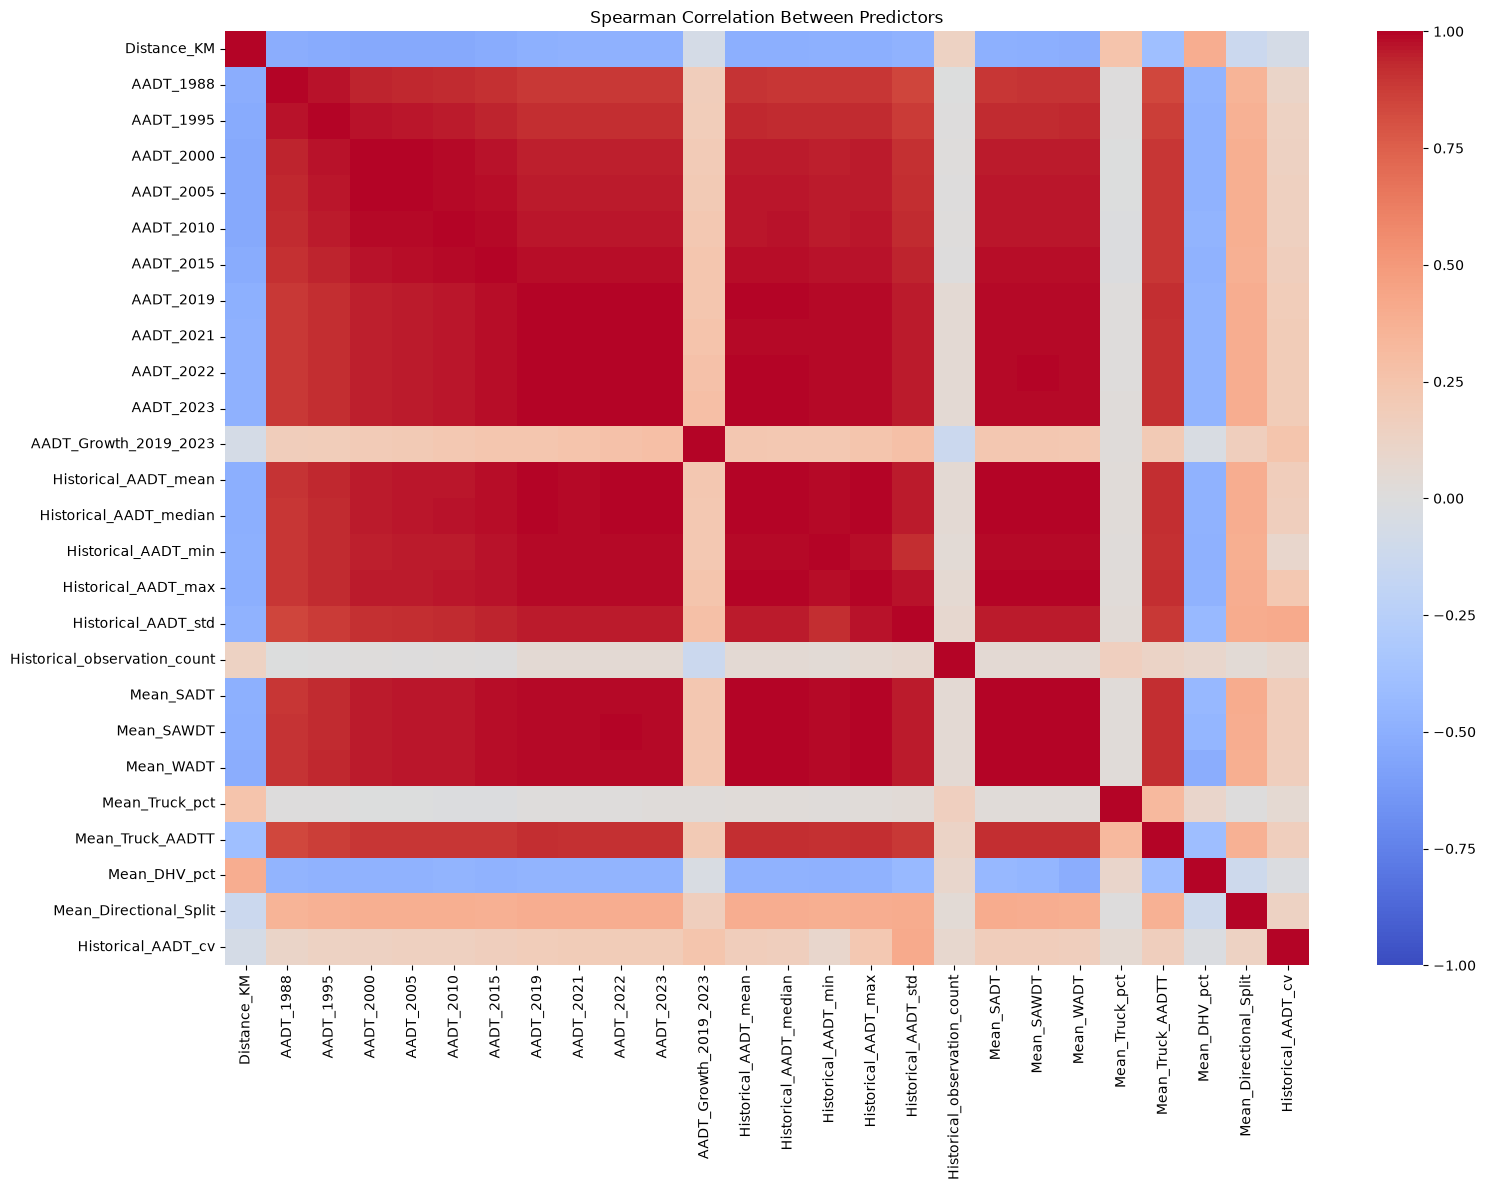

Number of highly correlated pairs: 116


In [9]:
# Calculate Spearman correlations between predictors
correlation_matrix = train[numeric_predictors].corr(
    method="spearman"
)

# Visualize correlations
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Predictors")
plt.tight_layout()
plt.show()

# Identify highly correlated predictor pairs
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) >= 0.95:
            high_correlations.append({
                "Variable 1": correlation_matrix.columns[i],
                "Variable 2": correlation_matrix.columns[j],
                "Correlation": correlation
            })

high_correlation_df = pd.DataFrame(
    high_correlations,
    columns=["Variable 1", "Variable 2", "Correlation"]
)

print("Number of highly correlated pairs:",
      len(high_correlation_df))

### Dimensionality reduction findings

No constant variables were found. There are 116 highly correlated predictor pairs, particularly historical AADT and seasonal traffic volumes. Retain all eligible predictors in the full model before backward selection, as required by the assignment.

### Logarithmic transformation

Following Tukey's ladder of powers, compare original and log-transformed training distributions and relationships.

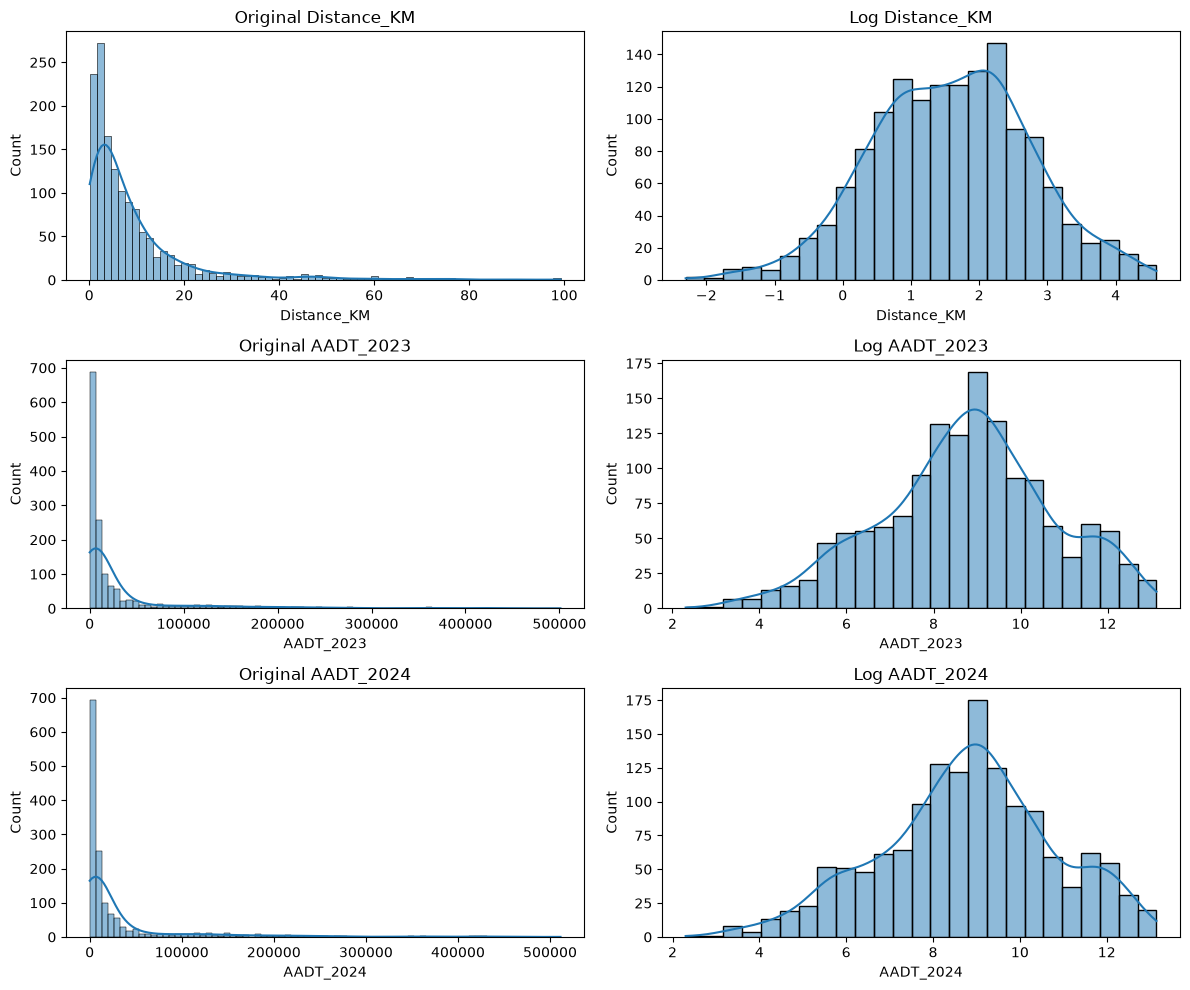

,Original Skewness,Log Skewness
Distance_KM,3.2967,-0.0869
AADT_2023,3.4212,-0.1952
AADT_2024,3.4123,-0.2060


In [10]:
# Examine original and logarithmic distributions
transform_variables = [
    "Distance_KM",
    "AADT_2023",
    "AADT_2024"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, column in enumerate(transform_variables):
    original = train[column]
    transformed = np.log(original)

    sns.histplot(
        original,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Original {column}")

    sns.histplot(
        transformed,
        kde=True,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"Log {column}")

plt.tight_layout()
plt.show()

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Original Skewness": [
        train[column].skew()
        for column in transform_variables
    ],
    "Log Skewness": [
        np.log(train[column]).skew()
        for column in transform_variables
    ]
}, index=transform_variables)

display(skewness_comparison.round(4))

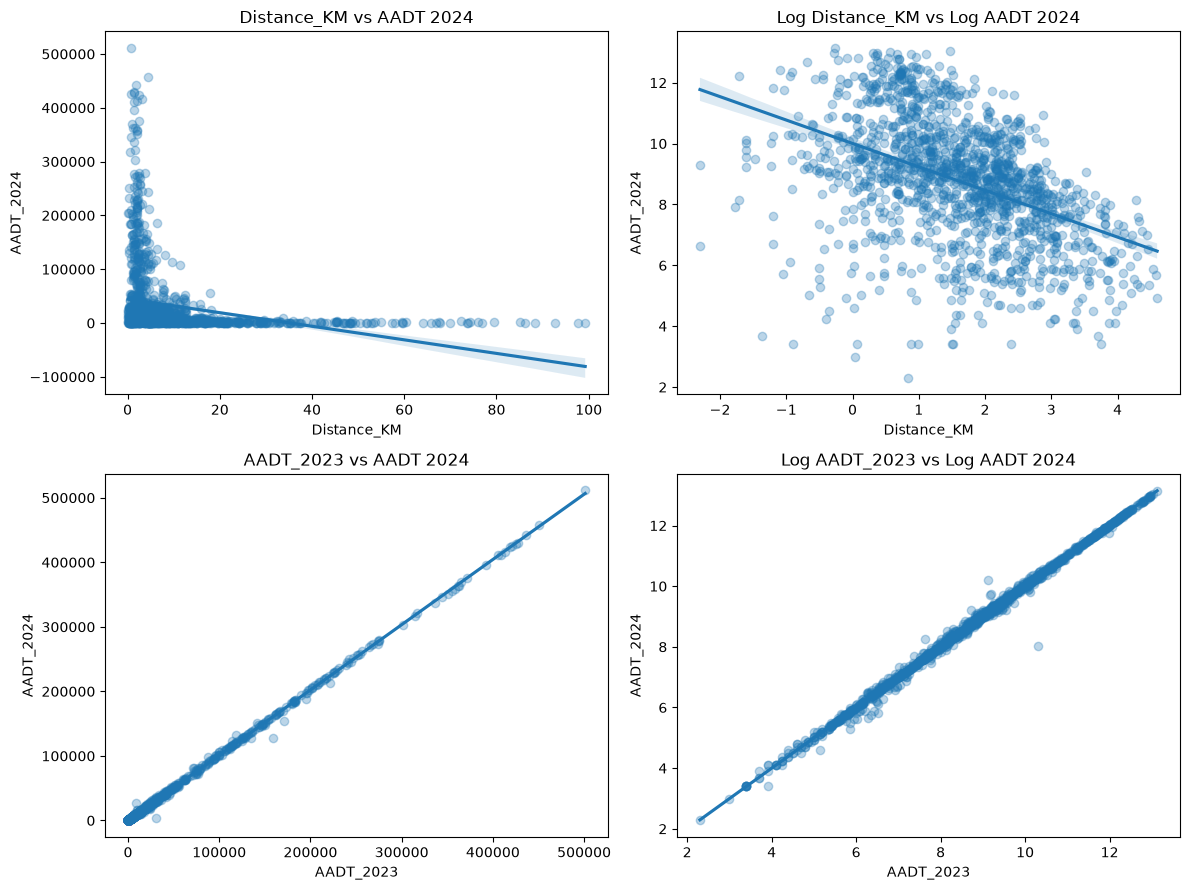

In [11]:
# Compare original and transformed relationships
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

predictors = ["Distance_KM", "AADT_2023"]

for i, column in enumerate(predictors):

    sns.regplot(
        x=train[column],
        y=train["AADT_2024"],
        ax=axes[i, 0],
        scatter_kws={"alpha": 0.3}
    )

    axes[i, 0].set_title(f"{column} vs AADT 2024")

    sns.regplot(
        x=np.log(train[column]),
        y=np.log(train["AADT_2024"]),
        ax=axes[i, 1],
        scatter_kws={"alpha": 0.3}
    )

    axes[i, 1].set_title(f"Log {column} vs Log AADT 2024")

plt.tight_layout()
plt.show()

### Transformation findings

Natural logarithms reduce the right skew of distance and AADT and reveal a clearer relationship between distance and traffic volume. Use log distance, log 2023 AADT and log 2024 AADT in the regression analysis. Retain original values for evaluation in vehicles per day.

In [12]:
# Apply logarithmic transformations to both datasets
for dataset in [train, test]:
    dataset["Log_Distance_KM"] = np.log(
        dataset["Distance_KM"]
    )

    dataset["Log_AADT_2023"] = np.log(
        dataset["AADT_2023"]
    )

    dataset["Log_AADT_2024"] = np.log(
        dataset["AADT_2024"]
    )

### Training and testing dataset validation

Compare numerical distributions using Kolmogorov–Smirnov tests and categorical distributions using chi-square tests at the 5% significance level. Group categorical levels representing less than 1% of training observations as Other to reduce sparse categories.

In [13]:
# Compare numerical distributions using the KS test
ks_results = []

for column in numeric_predictors + ["AADT_2024"]:

    statistic, p_value = ks_2samp(
        train[column],
        test[column]
    )

    ks_results.append({
        "Variable": column,
        "Training Mean": train[column].mean(),
        "Testing Mean": test[column].mean(),
        "KS Statistic": statistic,
        "P-value": p_value,
        "Significant Difference": p_value < 0.05
    })

ks_results = pd.DataFrame(ks_results)

display(ks_results.round(4))

print(
    "Variables with significant differences:",
    ks_results["Significant Difference"].sum()
)

,Variable,Training Mean,Testing Mean,KS Statistic,P-value,Significant Difference
0,Distance_KM,9.2592,8.7009,0.0512,0.4183,False
1,AADT_1988,15773.6420,14317.4862,0.0735,0.0836,False
2,AADT_1995,19968.7422,18413.7845,0.0568,0.2953,False
3,AADT_2000,23248.8735,20830.8564,0.0596,0.2448,False
4,AADT_2005,25626.9869,22554.3370,0.0597,0.2436,False
5,AADT_2010,27255.7844,23899.1436,0.0548,0.3357,False
6,AADT_2015,28927.6365,25190.3315,0.0673,0.1389,False
7,AADT_2019,30843.7526,26581.6851,0.0528,0.3806,False
8,AADT_2021,31435.7222,27014.4475,0.0548,0.3349,False
9,AADT_2022,31761.3822,27048.7569,0.0528,0.3808,False


Variables with significant differences: 0


In [14]:
# Group rare categorical levels using training frequencies
for column in categorical_columns:

    frequencies = train[column].value_counts(normalize=True)

    common_levels = frequencies[
        frequencies >= 0.01
    ].index

    for dataset in [train, test]:

        values = dataset[column].astype(str)

        dataset[column] = values.where(
            values.isin(common_levels),
            "Other"
        ).astype("category")

# Compare categorical distributions using chi-square
chi_results = []

for column in categorical_columns:

    contingency = pd.DataFrame({
        "Training": train[column].value_counts(),
        "Testing": test[column].value_counts()
    }).fillna(0)

    contingency = contingency[
        contingency.sum(axis=1) > 0
    ]

    statistic, p_value, dof, expected = chi2_contingency(
        contingency
    )

    chi_results.append({
        "Variable": column,
        "Chi-square Statistic": statistic,
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Minimum Expected Count": expected.min(),
        "Significant Difference": p_value < 0.05
    })


chi_results = pd.DataFrame(chi_results)

display(chi_results.round(4))

,Variable,Chi-square Statistic,Degrees of Freedom,P-value,Minimum Expected Count,Significant Difference
0,Highway_Type,3.0795,3,0.3795,1.2007,False
1,Region,0.9980,4,0.9101,47.4262,False
2,Pattern_Type,19.3622,11,0.0549,2.2012,False


### Validation findings

No numerical or categorical comparison was statistically significant at 0.05. Mean AADT was higher in training (32,724.64) than testing (28,194.48). Some expected counts for Highway_Type and Pattern_Type were small, so interpret those chi-square results cautiously. The split is sufficiently comparable for our analysis.

## 4. Simple linear regression

Both models predict log-transformed 2024 AADT using the same observations. Model 1 uses log distance; Model 2 uses log 2023 AADT.

In [15]:
# Define the dependent variable
y_train = train["Log_AADT_2024"]
y_test = test["Log_AADT_2024"]

# Define the independent variable
X_train_1 = sm.add_constant(train[["Log_Distance_KM"]])
X_test_1 = sm.add_constant(test[["Log_Distance_KM"]])

# Fit the first simple linear regression model
slr1 = sm.OLS(y_train, X_train_1).fit()

# Display regression results
print(slr1.summary().tables[1])

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              10.0035      0.080    125.613      0.000       9.847      10.160
Log_Distance_KM    -0.7692      0.041    -18.980      0.000      -0.849      -0.690


In [16]:
# Define the second independent variable
X_train_2 = sm.add_constant(train[["Log_AADT_2023"]])
X_test_2 = sm.add_constant(test[["Log_AADT_2023"]])

# Fit the second simple linear regression model
slr2 = sm.OLS(y_train, X_train_2).fit()

# Display regression results
print(slr2.summary().tables[1])

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.0135      0.013     -1.008      0.314      -0.040       0.013
Log_AADT_2023     1.0027      0.001    675.554      0.000       1.000       1.006


### Model evaluation

Compare training F-statistics, p-values, training/testing R² and adjusted training R² on the log scale. Convert predictions to AADT using a training-residual smearing factor before calculating train and test RMSE in vehicles per day.

In [17]:
# Evaluate regression models in original AADT units
def evaluate_model(name, model, X_train, X_test):

    # Calculate logarithmic predictions
    train_log_pred = model.predict(X_train)
    test_log_pred = model.predict(X_test)

    # Correct retransformation bias using training residuals
    smearing_factor = np.exp(model.resid).mean()

    # Convert predictions back to original traffic units
    train_pred = np.exp(train_log_pred) * smearing_factor
    test_pred = np.exp(test_log_pred) * smearing_factor

    # Calculate RMSE in original AADT units
    train_rmse = np.sqrt(
        mean_squared_error(train["AADT_2024"], train_pred)
    )

    test_rmse = np.sqrt(
        mean_squared_error(test["AADT_2024"], test_pred)
    )

    return {
        "Model": name,
        "F-statistic": model.fvalue,
        "F-test P-value": model.f_pvalue,
        "Training R-squared (Log Scale)": model.rsquared,
        "Testing R-squared (Log Scale)": r2_score(
            test["Log_AADT_2024"], test_log_pred
        ),
        "Adjusted R-squared (Log Scale)": model.rsquared_adj,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse
    }

# Compare the two simple regression models
slr_results = pd.DataFrame([
    evaluate_model(
        "SLR 1 - Distance",
        slr1, X_train_1, X_test_1
    ),
    evaluate_model(
        "SLR 2 - Historical AADT",
        slr2, X_train_2, X_test_2
    )
])

display(slr_results.round(4))

,Model,F-statistic,F-test P-value,Training R-squared (Log Scale),Testing R-squared (Log Scale),Adjusted R-squared (Log Scale),Training RMSE,Testing RMSE
0,SLR 1 - Distance,360.2347,0.0,0.1996,0.1872,0.1990,70757.3399,63158.6396
1,SLR 2 - Historical AADT,456373.1455,0.0,0.9968,0.9981,0.9968,2182.8042,1528.3398


### Simple regression findings

Both overall F-tests are significant. The historical AADT model is superior: adjusted training R² is 0.9968 versus 0.1990, and testing RMSE is 1,528.34 versus 63,158.64 vehicles/day. Segment distance alone is a much weaker predictor.

## 5. Multiple linear regression

Fit all 29 eligible predictors (44 coefficients after categorical encoding), keeping log 2024 AADT as the response. Then apply backward selection to reduce complexity.

In [18]:
# Select all eligible independent variables
mlr_predictors = [
    column for column in study.columns
    if column not in [
        "AADT_2024",
        "Distance_KM",
        "AADT_2023"
    ]
]

# Include transformed predictors
mlr_predictors.extend([
    "Log_Distance_KM",
    "Log_AADT_2023"
])

# Construct the regression formula
formula = (
    "Log_AADT_2024 ~ " +
    " + ".join(mlr_predictors)
)

print("Number of predictors:", len(mlr_predictors))
print("\nRegression formula:")
print(formula)

# Fit the full multiple regression model
mlr_full = smf.ols(
    formula=formula,
    data=train
).fit()

print(mlr_full.summary().tables[1])

Number of predictors: 29

Regression formula:
Log_AADT_2024 ~ AADT_1988 + AADT_1995 + AADT_2000 + AADT_2005 + AADT_2010 + AADT_2015 + AADT_2019 + AADT_2021 + AADT_2022 + AADT_Growth_2019_2023 + Historical_AADT_mean + Historical_AADT_median + Historical_AADT_min + Historical_AADT_max + Historical_AADT_std + Historical_observation_count + Mean_SADT + Mean_SAWDT + Mean_WADT + Mean_Truck_pct + Mean_Truck_AADTT + Mean_DHV_pct + Mean_Directional_Split + Historical_AADT_cv + Highway_Type + Region + Pattern_Type + Log_Distance_KM + Log_AADT_2023
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                        0.0566      0.046      1.230      0.219      -0.034       0.147
Highway_Type[T.KING]            -0.0303      0.013     -2.418      0.016      -0.055      -0.006
Highway_Type[T.Other]           -0.2125      0.063     -3.374      0

### Initial multiple regression findings

The full model achieves adjusted training R² of 0.9969, but testing RMSE is 3,581.33 vehicles/day, substantially higher than for the historical AADT simple regression. The high correlations and many large predictor p-values motivate variable selection.

### Backward variable selection

Fit the full model on the training set. Iteratively remove the predictor with the highest partial F-test p-value above 0.05. Test categorical variables as complete terms and retain terms meeting the threshold.

In [19]:
# Initialize backward variable selection
remaining_predictors = mlr_predictors.copy()

selection_history = []
significance_level = 0.05
iteration = 1

while remaining_predictors:

    # Fit the current model
    current_formula = (
        "Log_AADT_2024 ~ " +
        " + ".join(remaining_predictors)
    )

    current_model = smf.ols(
        current_formula,
        data=train
    ).fit()

    # Test each complete predictor term
    term_tests = current_model.wald_test_terms(
        scalar=True
    ).table

    term_pvalues = (
        term_tests["pvalue"]
        .drop("Intercept", errors="ignore")
        .astype(float)
    )

    # Identify the least significant predictor
    worst_predictor = term_pvalues.idxmax()
    worst_pvalue = term_pvalues.max()

    # Stop when all remaining predictors are significant
    if worst_pvalue <= significance_level:
        break

    selection_history.append({
        "Iteration": iteration,
        "Removed Predictor": worst_predictor,
        "P-value": worst_pvalue,
        "Adjusted R-squared": current_model.rsquared_adj,
        "Predictors Before Removal": len(remaining_predictors)
    })

    remaining_predictors.remove(worst_predictor)
    iteration += 1

# Display the variable removal process
selection_history = pd.DataFrame(selection_history)

display(selection_history.round(6))

print("Original predictors:", len(mlr_predictors))
print("Remaining predictors:", len(remaining_predictors))
print("\nSelected predictors:")

for predictor in remaining_predictors:
    print(predictor)

,Iteration,Removed Predictor,P-value,Adjusted R-squared,Predictors Before Removal
0,1,Historical_observation_count,0.998979,0.996885,29
1,2,Historical_AADT_min,0.977825,0.996887,28
2,3,AADT_2005,0.913018,0.996890,27
3,4,AADT_2000,0.944469,0.996892,26
4,5,Mean_SAWDT,0.881842,0.996894,25
5,6,AADT_1988,0.873369,0.996896,24
6,7,Historical_AADT_cv,0.867717,0.996898,23
7,8,Historical_AADT_median,0.840134,0.996900,22
8,9,Mean_Truck_AADTT,0.808706,0.996903,21
9,10,AADT_2010,0.738736,0.996905,20


Original predictors: 29
Remaining predictors: 7

Selected predictors:
AADT_2019
AADT_2021
AADT_2022
Mean_Truck_pct
Highway_Type
Region
Log_AADT_2023


In [20]:
# Construct the final regression formula
final_formula = (
    "Log_AADT_2024 ~ " +
    (" + ".join(remaining_predictors)
     if remaining_predictors else "1")
)

print("Final regression formula:")
print(final_formula)

# Fit the reduced multiple regression model
mlr_reduced = smf.ols(
    formula=final_formula,
    data=train
).fit()

print(mlr_reduced.summary().tables[1])

Final regression formula:
Log_AADT_2024 ~ AADT_2019 + AADT_2021 + AADT_2022 + Mean_Truck_pct + Highway_Type + Region + Log_AADT_2023
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.0348      0.037      0.941      0.347      -0.038       0.107
Highway_Type[T.KING]      -0.0288      0.011     -2.580      0.010      -0.051      -0.007
Highway_Type[T.Other]     -0.1875      0.060     -3.151      0.002      -0.304      -0.071
Highway_Type[T.SEC]       -0.0653      0.017     -3.735      0.000      -0.100      -0.031
Region[T.EAST]             0.0248      0.011      2.336      0.020       0.004       0.046
Region[T.NORTHEASTERN]     0.0262      0.012      2.253      0.024       0.003       0.049
Region[T.NORTHWESTERN]     0.0467      0.014      3.309      0.001       0.019       0.074
Region[T.WEST]             0.0227      0.011    

In [21]:
# Evaluate the full multiple regression model
mlr_full_results = pd.DataFrame([
    evaluate_model(
        "MLR - Full",
        mlr_full,
        train,
        test
    )
])

# Baseline: assume traffic remains unchanged
baseline_train_rmse = np.sqrt(
    mean_squared_error(
        train["AADT_2024"],
        train["AADT_2023"]
    )
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(
        test["AADT_2024"],
        test["AADT_2023"]
    )
)

# Evaluate the reduced multiple regression model
mlr_reduced_results = pd.DataFrame([
    evaluate_model(
        "MLR - Reduced",
        mlr_reduced,
        train,
        test
    )
])

# Include all regression models
model_comparison = pd.concat(
    [
        slr_results,
        mlr_full_results,
        mlr_reduced_results
    ],
    ignore_index=True
)

# Include the previous-year prediction benchmark
baseline_results = pd.DataFrame([{
    "Model": "Baseline - 2023 AADT",
    "Training RMSE": baseline_train_rmse,
    "Testing RMSE": baseline_test_rmse
}])

final_comparison = pd.concat(
    [model_comparison, baseline_results],
    ignore_index=True
)

display(final_comparison.round(4))

,Model,F-statistic,F-test P-value,Training R-squared (Log Scale),Testing R-squared (Log Scale),Adjusted R-squared (Log Scale),Training RMSE,Testing RMSE
0,SLR 1 - Distance,360.2347,0.0,0.1996,0.1872,0.1990,70757.3399,63158.6396
1,SLR 2 - Historical AADT,456373.1455,0.0,0.9968,0.9981,0.9968,2182.8042,1528.3398
2,MLR - Full,10518.9476,0.0,0.9970,0.9979,0.9969,2504.5485,3581.3345
3,MLR - Reduced,38889.1781,0.0,0.9969,0.9980,0.9969,2285.5303,3653.2609
4,Baseline - 2023 AADT,NaN,NaN,NaN,NaN,NaN,2042.4966,1425.6718


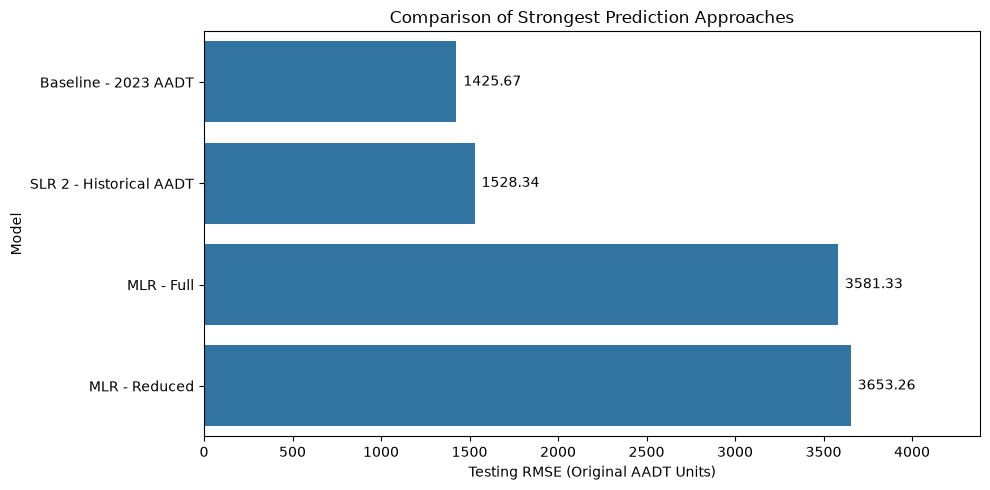

In [22]:
# Compare the four strongest prediction approaches
closer_comparison = final_comparison[
    final_comparison["Model"] != "SLR 1 - Distance"
].sort_values("Testing RMSE")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=closer_comparison,
    x="Testing RMSE",
    y="Model"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

plt.xlim(0, closer_comparison["Testing RMSE"].max() * 1.2)
plt.title("Comparison of Strongest Prediction Approaches")
plt.xlabel("Testing RMSE (Original AADT Units)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

### Backward selection findings

The reduced model retains 7 of 29 predictors (75.86% reduction) and nearly identical adjusted R². Testing RMSE rises slightly from 3,581.33 to 3,653.26 vehicles/day. The reduced MLR is preferred for parsimony, although neither MLR improves on the historical AADT simple regression.

## 6. Conclusion

The historical AADT simple regression is the preferred regression model: it is simpler and has the lowest testing RMSE (1,528.34 vehicles/day). The seven-predictor multiple regression provides a more concise alternative to the full model but does not improve predictions.

The previous-year AADT benchmark has the lowest testing RMSE overall (1,425.67 vehicles/day). In this comparison, additional predictors bring little predictive benefit. Strong historical predictor correlations limit individual coefficient interpretation. AADT measures traffic volume rather than congestion directly, and the random split evaluates held-out segments within the 2024 dataset, not entirely new years.